# Halo posterior sampling

Inspect the posterior summaries and diagnostics for the baseline fits from notebook 4.
Leave `RUN_MCMC = False` to view saved results, or set it to `True` to run or resume sampling.

The DDO154 and CamB pilot runs check the sampler before the full-sample analysis.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

RUN_MCMC = False

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'models' / 'mcmc.py').is_file())
output = root / 'data' / 'processed' / 'halo_fits' / 'mcmc'

if RUN_MCMC:
    if str(root) not in sys.path:
        sys.path.insert(0, str(root))
    from utils.mcmc_analysis import run_analysis

    run_analysis(output, workers=4)


,galaxy,model,scipy_chi2,steps,converged,boundary_sensitive,pilot_grid_cdf_error,pilot_chain_cdf_error
0,DDO154,nfw,117.712081,6000,True,False,0.001476,0.003322
1,DDO154,burkert,12.436461,12000,True,False,0.004368,0.004442
2,CamB,nfw,42.060263,16000,True,False,0.000030,0.006366
3,CamB,burkert,31.596657,10000,True,False,0.000529,0.002157


model    converged  boundary_sensitive
burkert  True       False                 108
nfw      False      False                   1
         True       False                 102
                    True                    5
dtype: int64

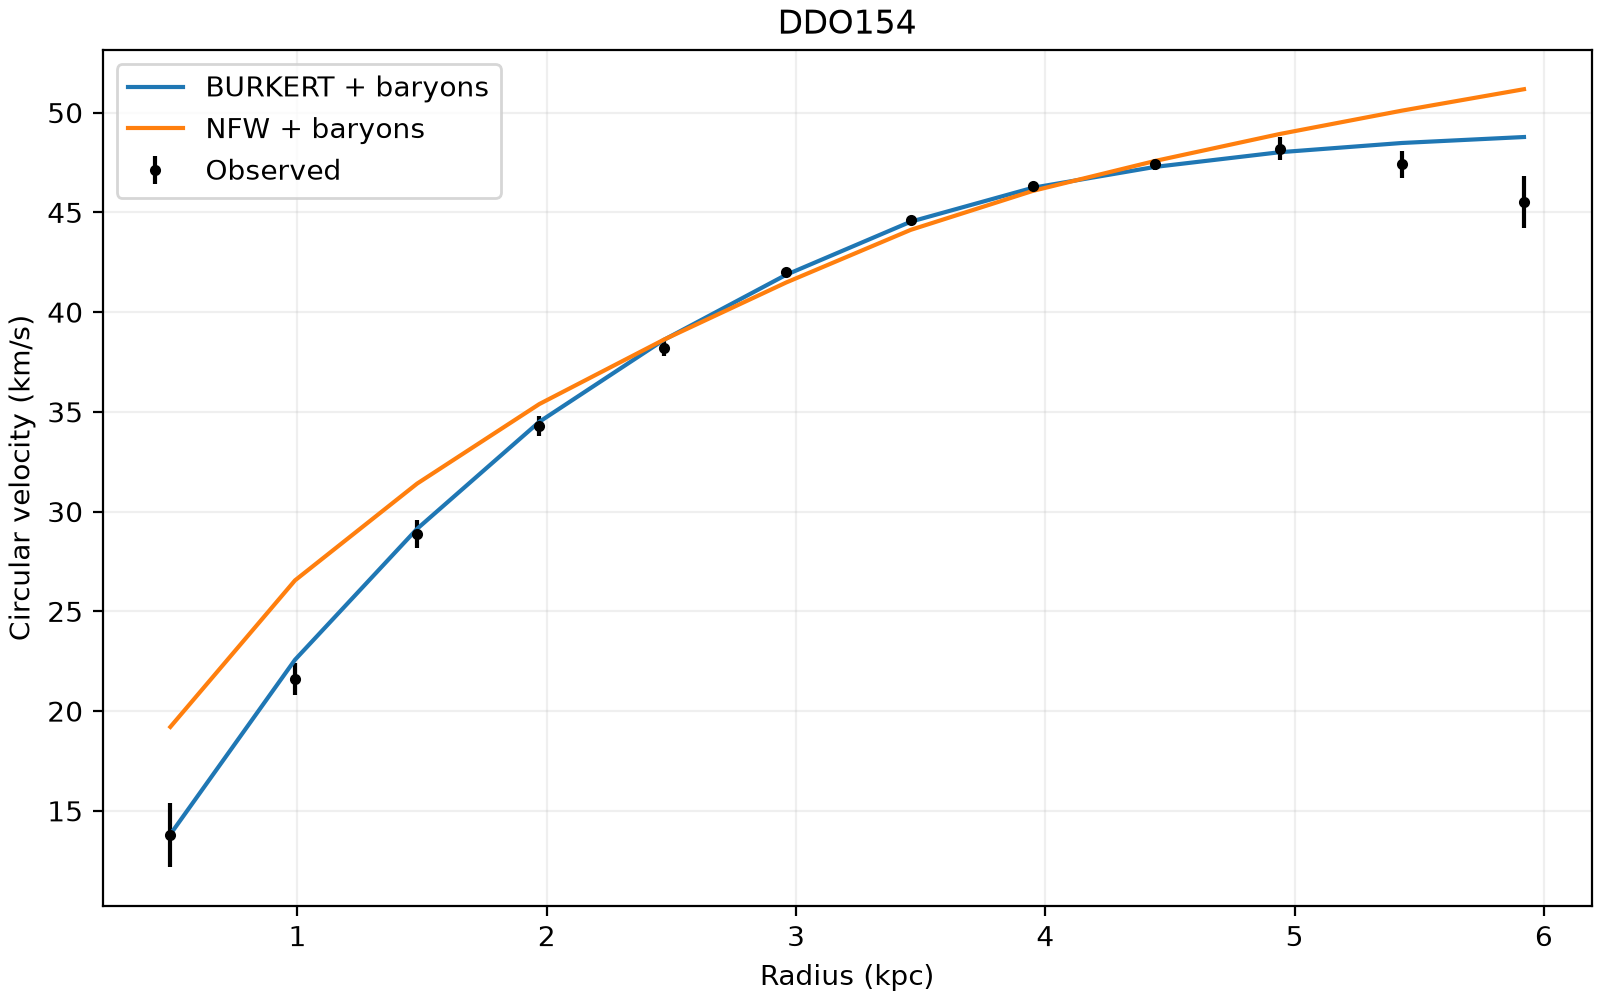

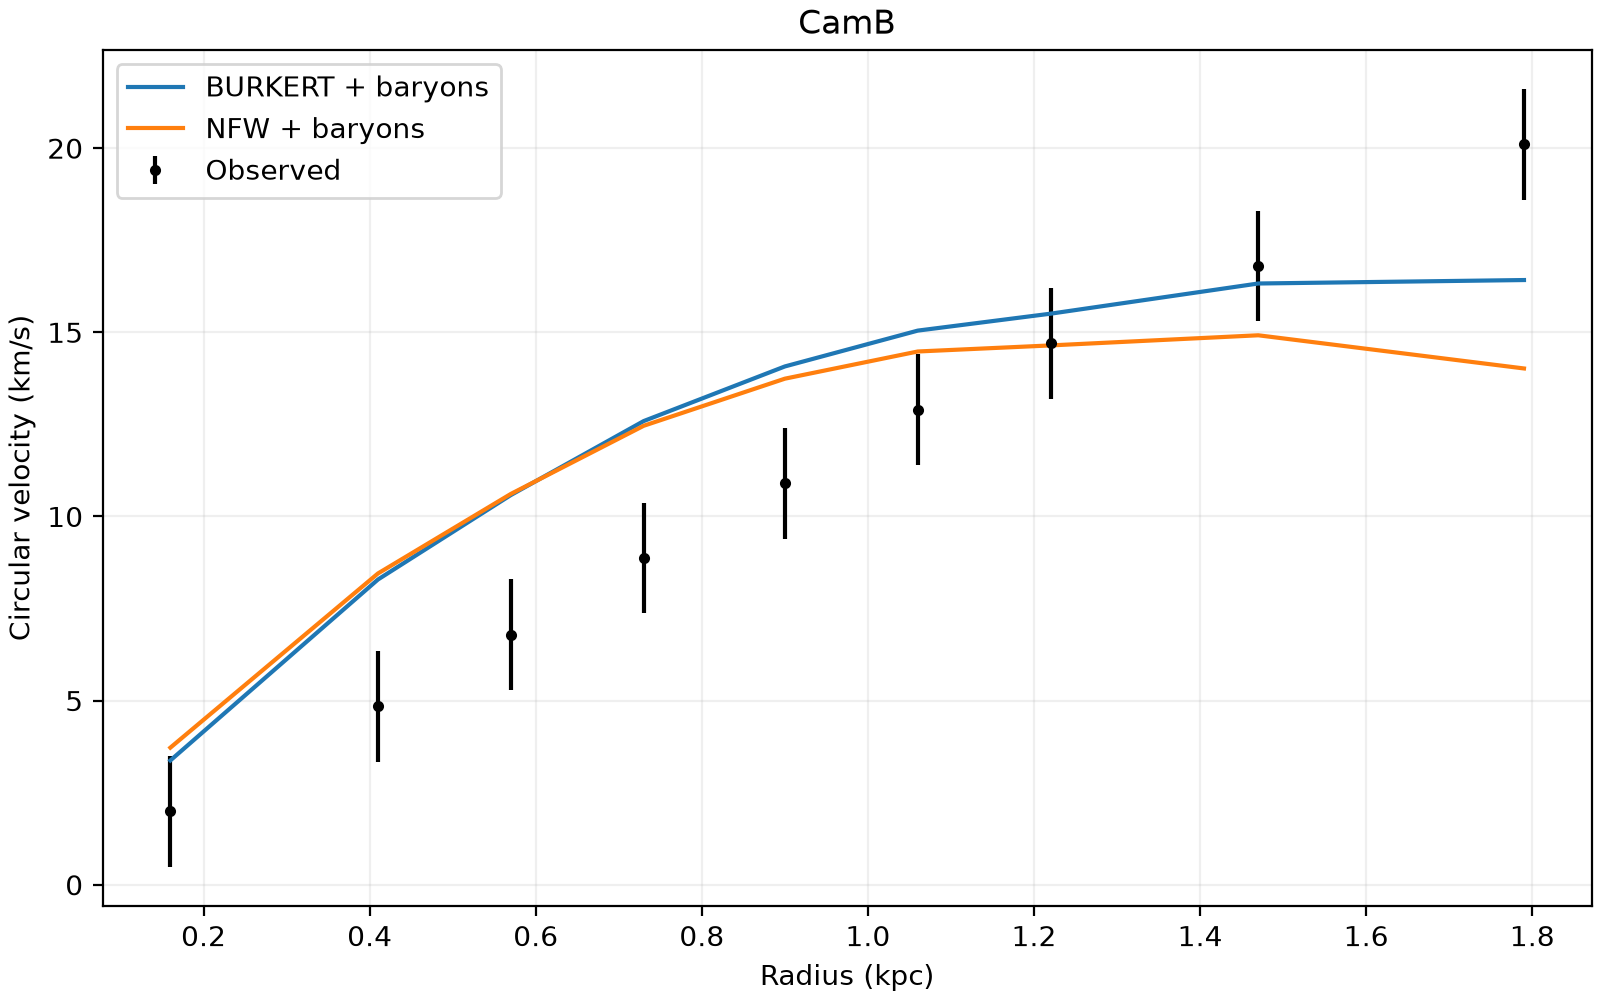

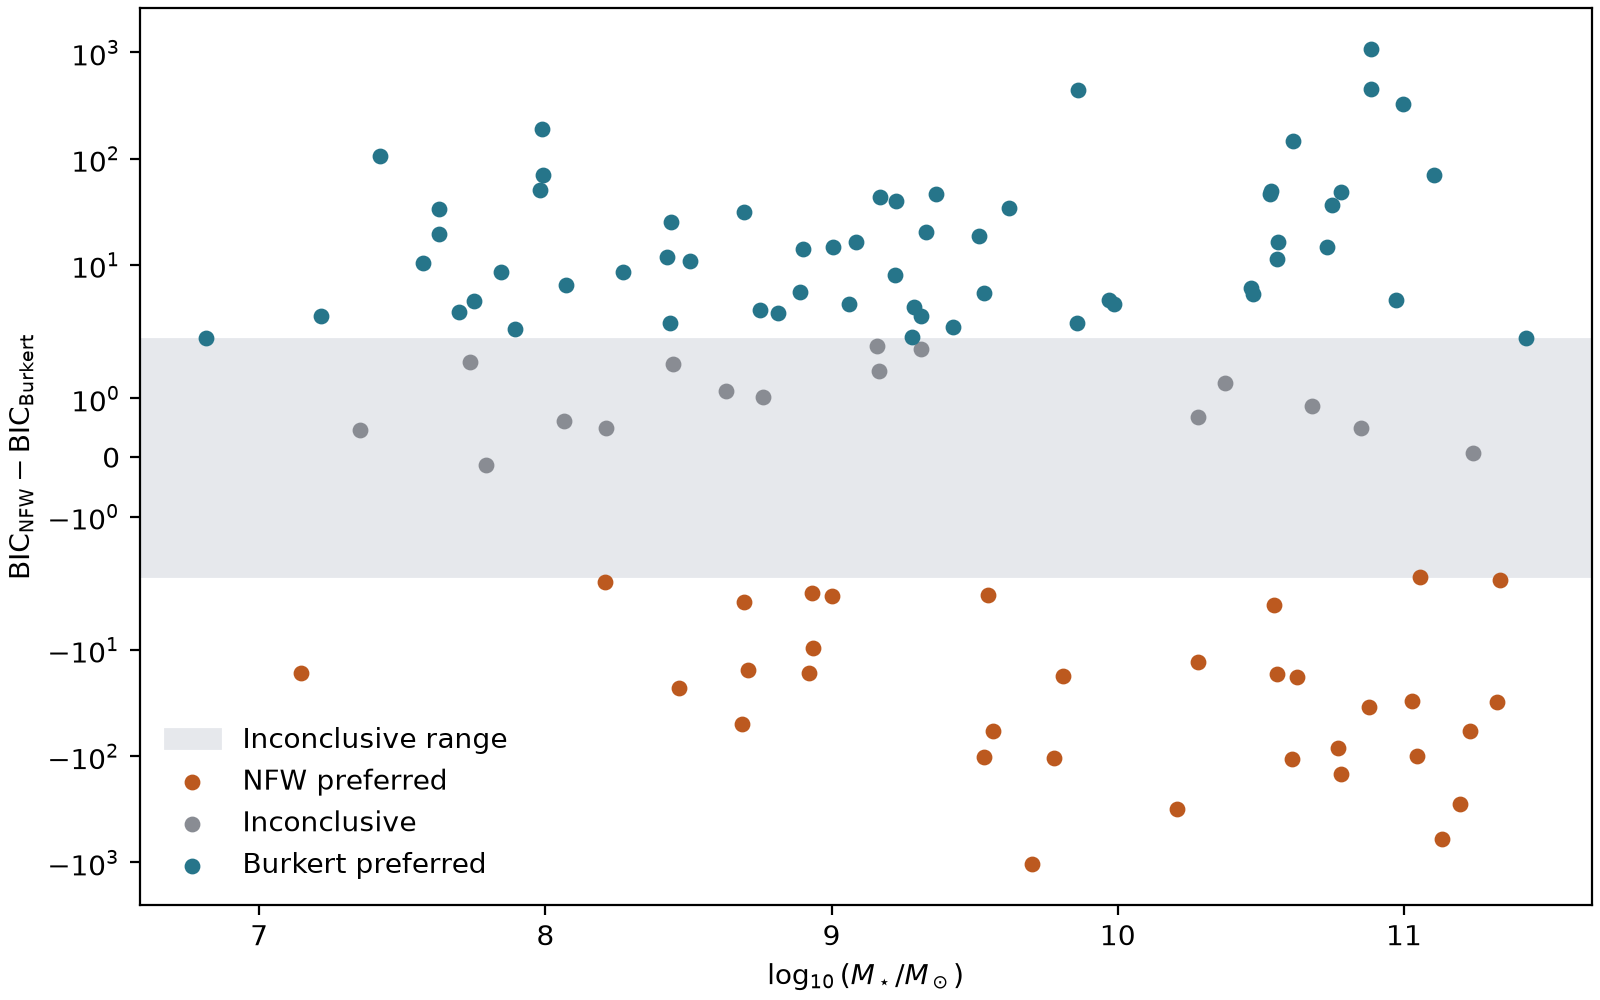

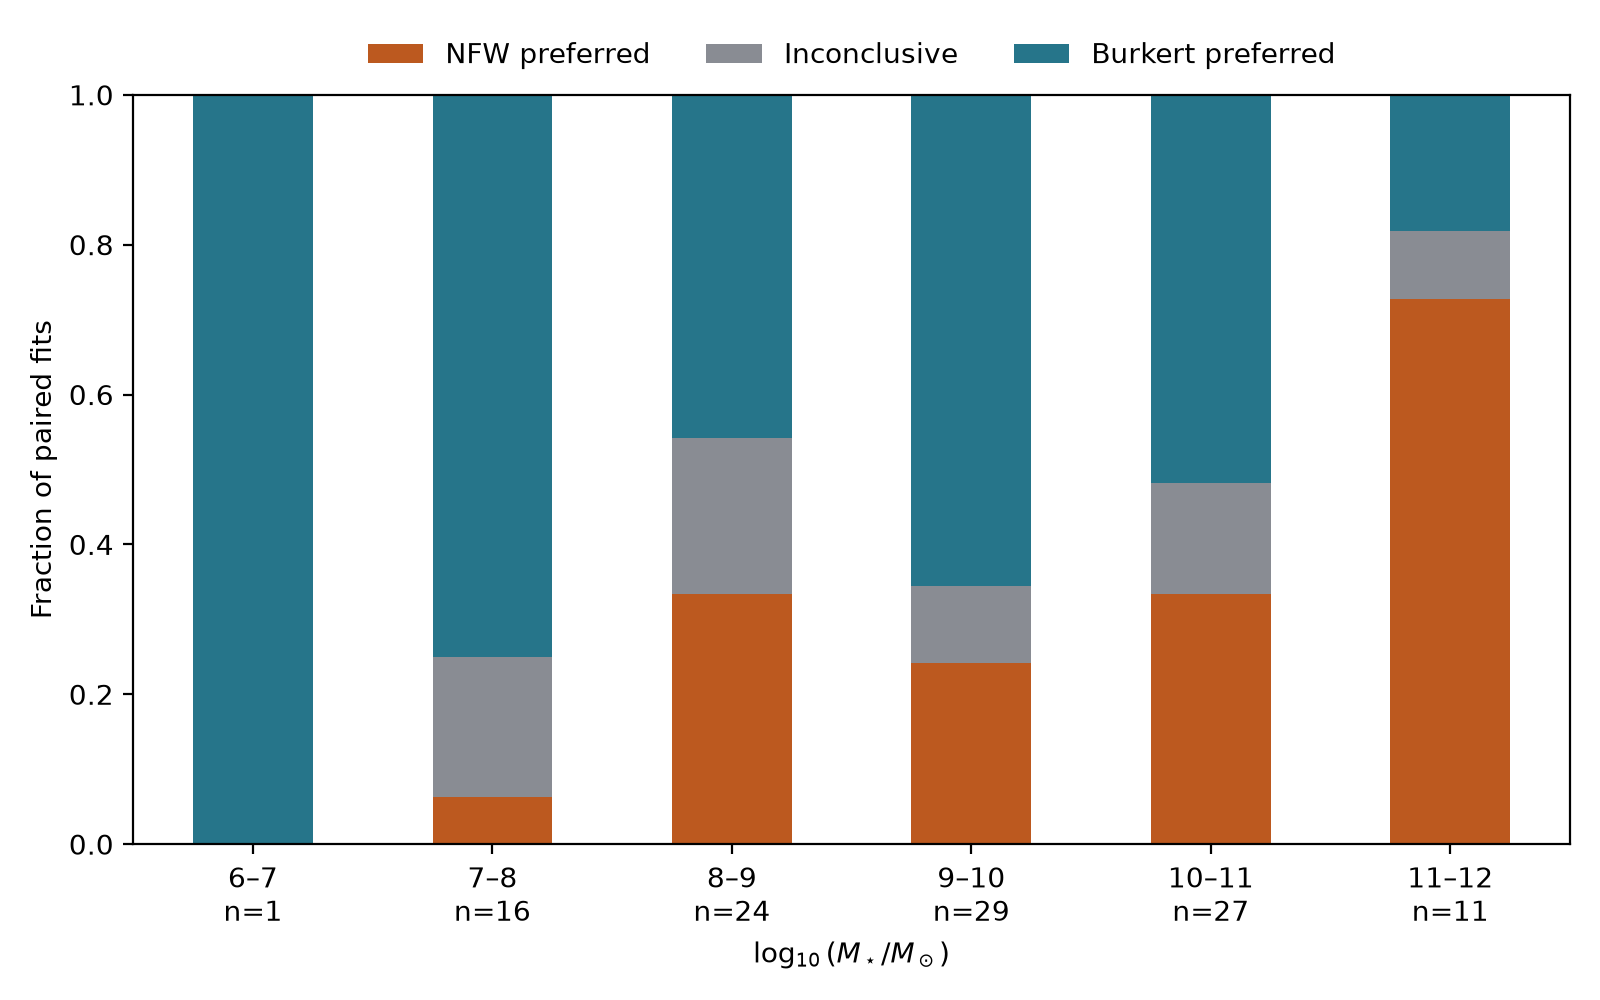

In [2]:
figures = output / 'figures'
plots = [
    'DDO154_rotation_curve.png',
    'CamB_rotation_curve.png',
    'stellar_mass_delta_bic.png',
    'stellar_mass_binned_preference.png',
]
required = [output / 'pilot_summary.csv', output / 'results.csv']
required += [figures / plot for plot in plots]
missing = [path.name for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        f"Missing saved outputs in {output}: {', '.join(missing)}. "
        "Set RUN_MCMC = True and rerun the notebook to generate them."
    )

pilot = pd.read_csv(output / 'pilot_summary.csv')
results = pd.read_csv(output / 'results.csv')
display(pilot[['galaxy', 'model', 'scipy_chi2', 'steps', 'converged',
               'boundary_sensitive', 'pilot_grid_cdf_error', 'pilot_chain_cdf_error']])
display(results.groupby(['model', 'converged', 'boundary_sensitive'], dropna=False).size())
for plot in plots:
    display(Image(filename=str(figures / plot)))


## What the rotation curves constrain
The shaded bands summarize the central 68% of total model velocities at each measured radius using paired mass and concentration draws after burn-in. The dots and error bars show the observations.

The two scatter panels use identical BIC differences and a shared color scale for each halo model’s mass uncertainty. A width of one dex spans a factor of ten in halo mass.

The binned points show observed preference fractions. Vertical lines show central 68% marginal credible intervals for the underlying fractions under a multinomial model with a symmetric Dirichlet(0.5, 0.5, 0.5) prior per bin. These intervals describe counting uncertainty conditional on the BIC classifications.

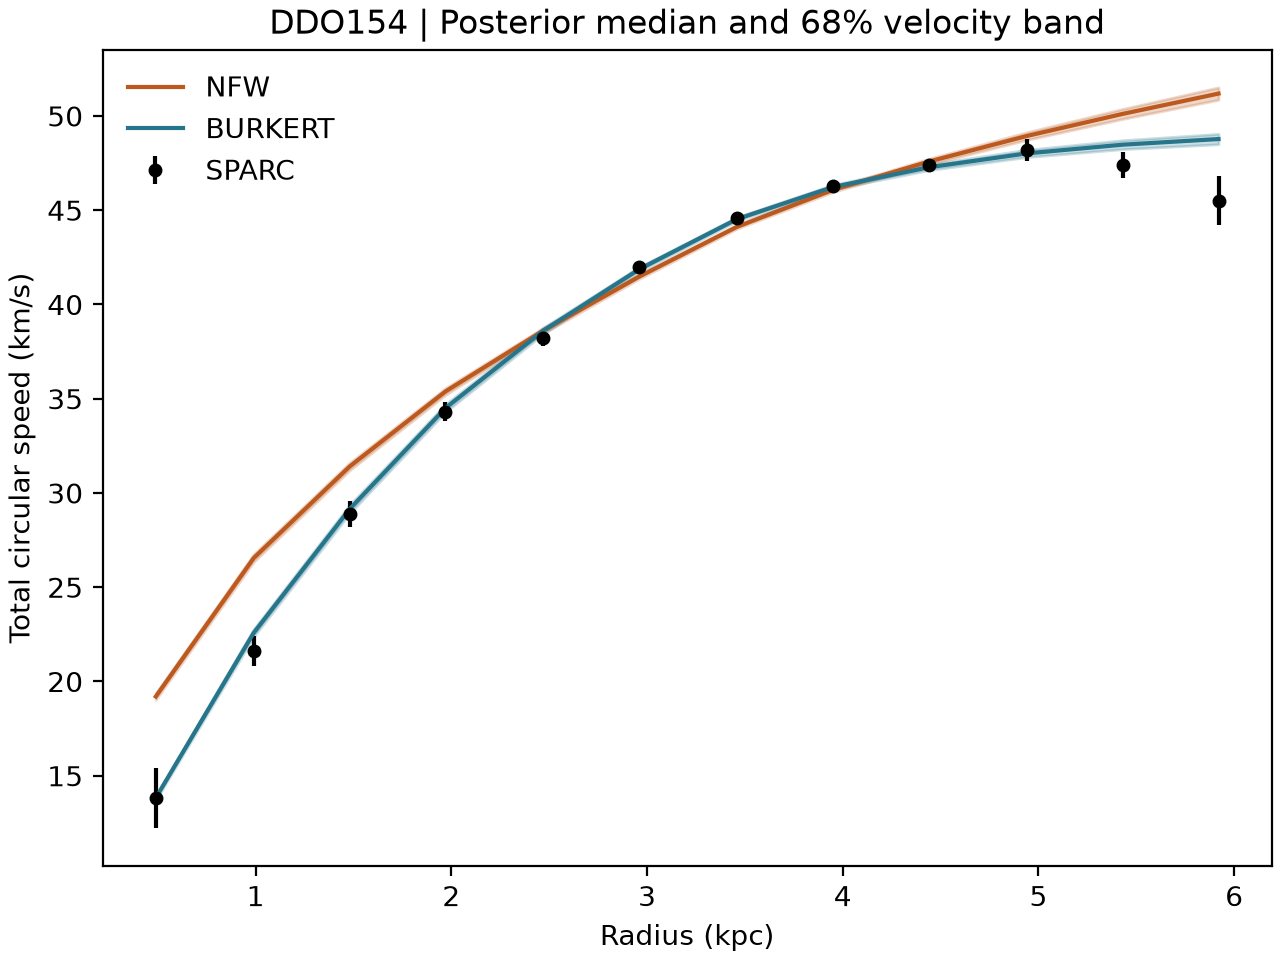

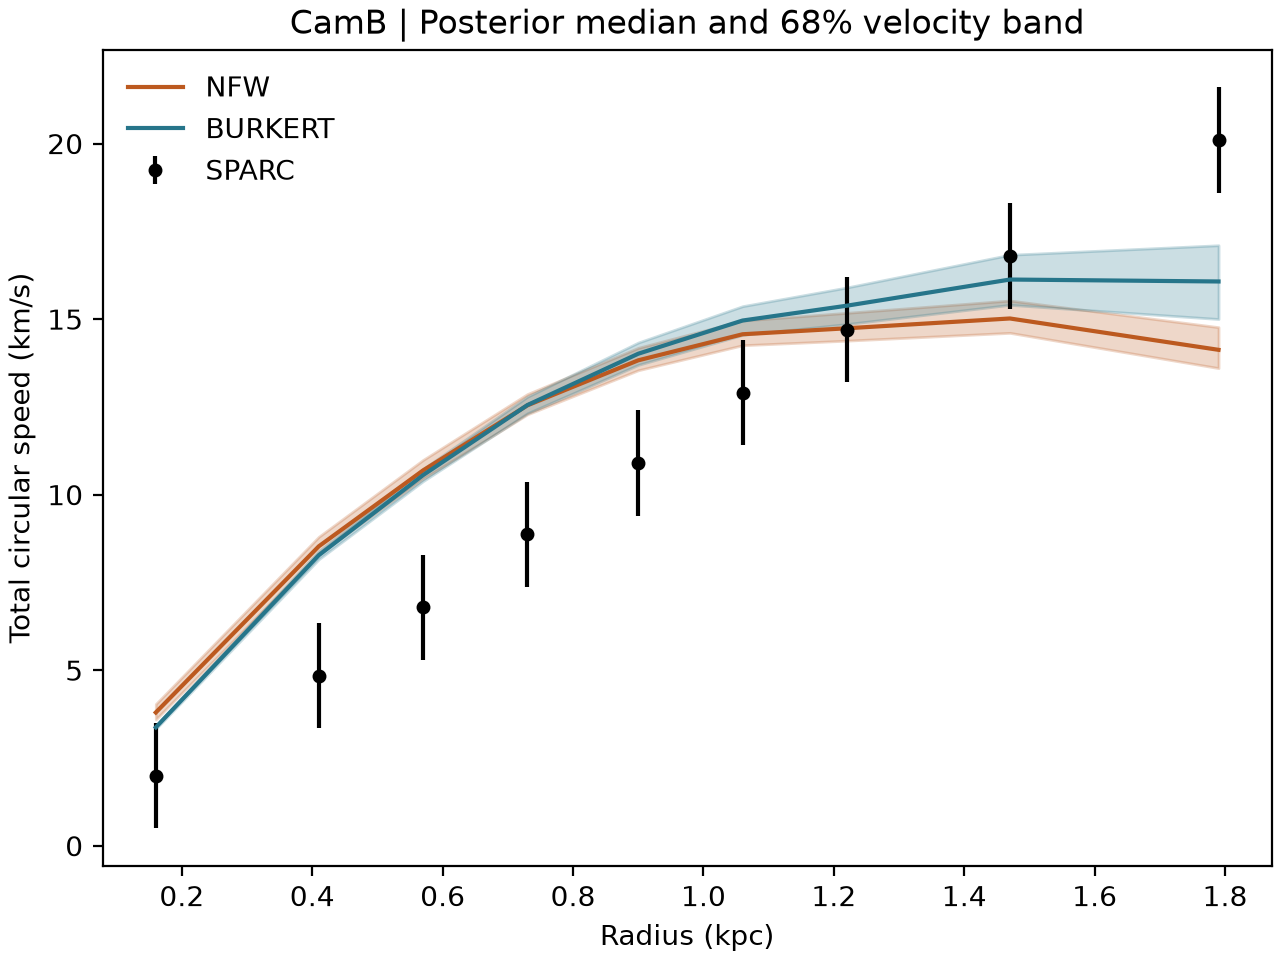

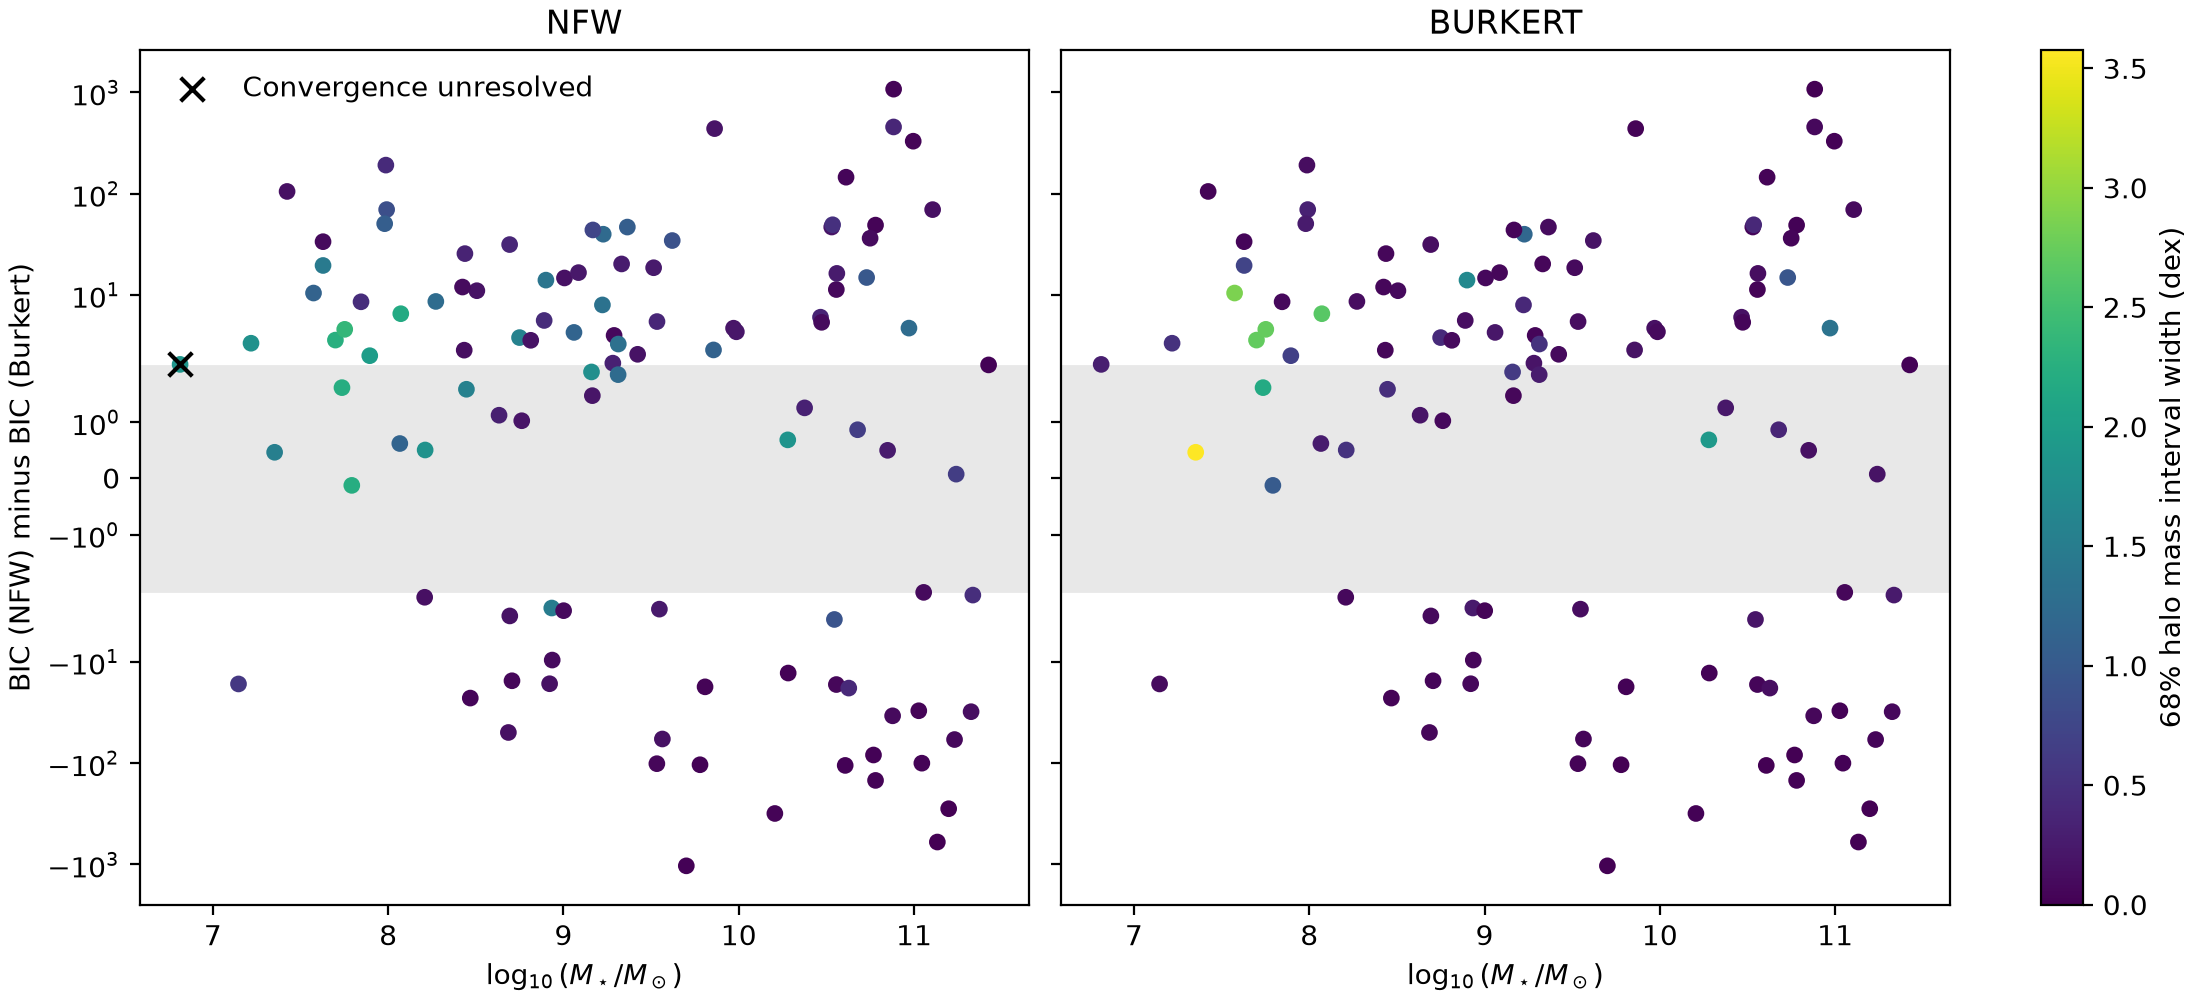

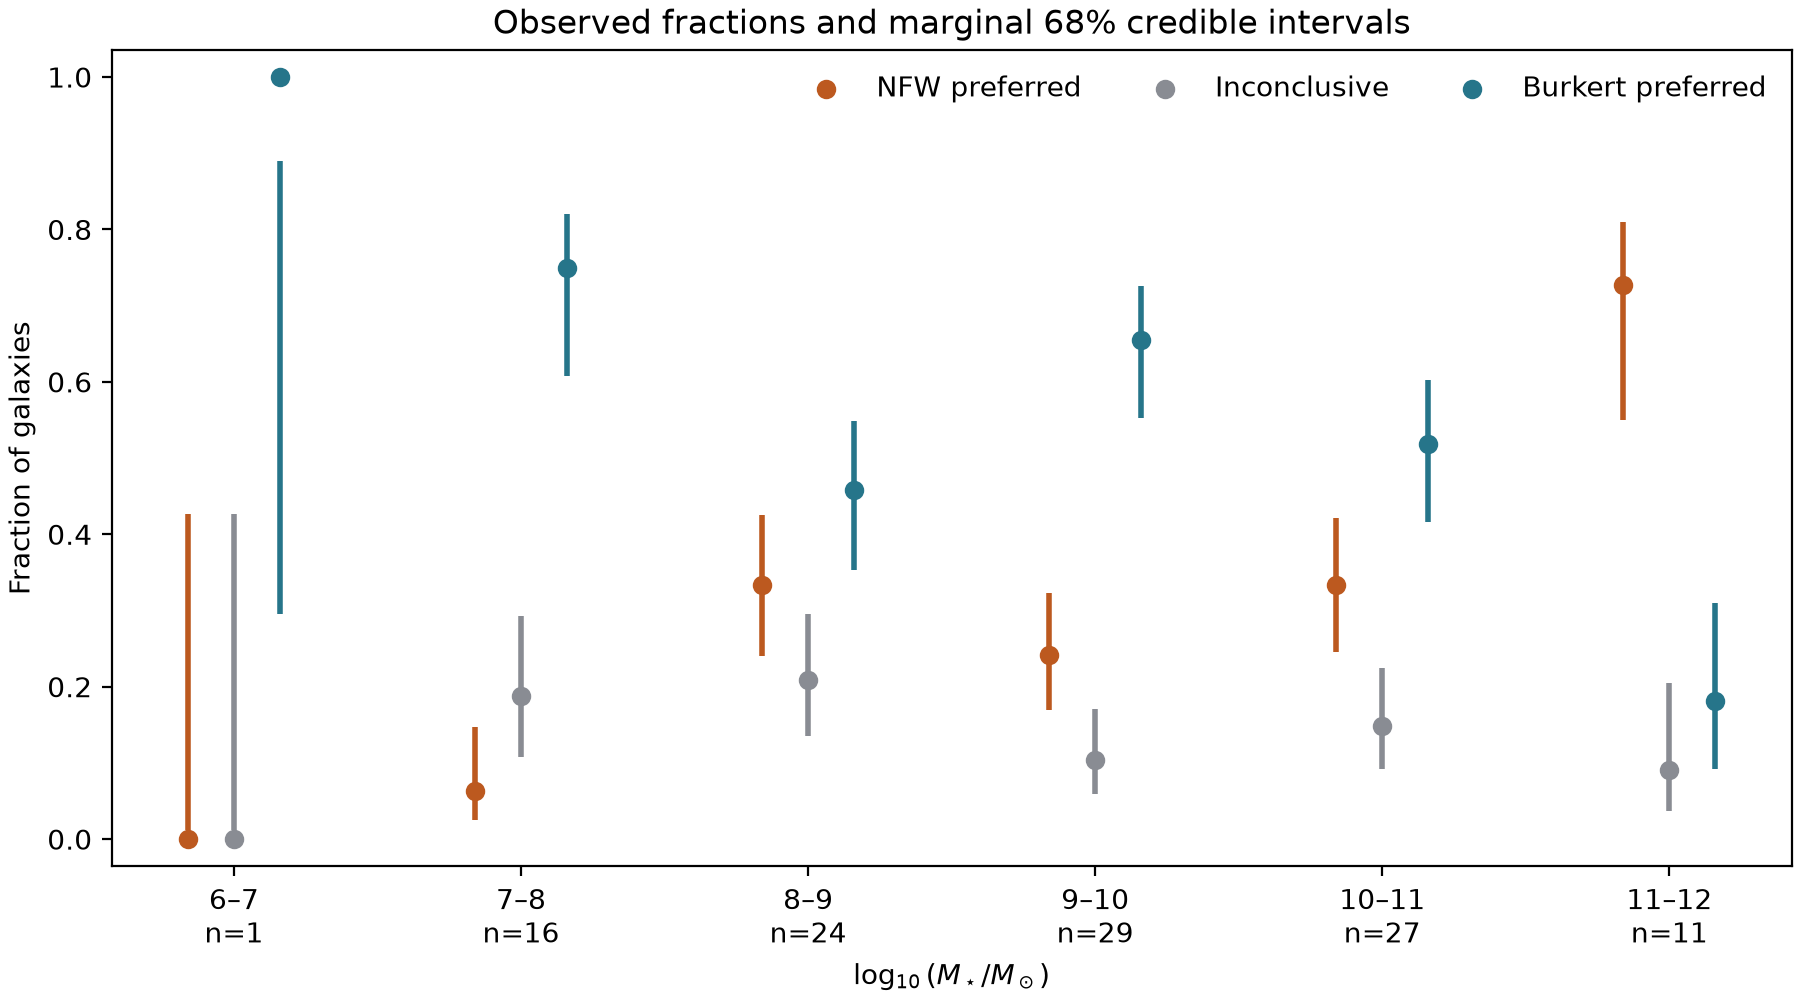

In [3]:
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from utils.mcmc_figures import export_velocity_bands, export_precision_scatter, export_fraction_intervals
from models.results import FitConfig
import json

baseline = output.parent
processed = baseline.parent
config = FitConfig(**json.loads((baseline / 'fit_config.json').read_text())['fit'])
curves = pd.read_csv(processed / 'selected_galaxy_rotation_curves.csv')
if (output / 'chains').is_dir() or any(
    not (figures / f'{galaxy}_velocity_bands.png').is_file() for galaxy in pilot.galaxy.unique()
):
    export_velocity_bands(pilot, dict(tuple(curves.groupby('galaxy'))), config, output)
export_precision_scatter(results, output)
export_fraction_intervals(pd.read_csv(output / 'stellar_mass_bins.csv'), output)
for name in ['DDO154_velocity_bands', 'CamB_velocity_bands', 'stellar_mass_posterior_precision', 'stellar_mass_fraction_intervals']:
    display(Image(filename=str(figures / f'{name}.png')))

## MCMC posterior diagnostics
The corner plots show the marginalized and joint posterior distributions for log halo mass and concentration. Dotted lines mark the 16th, 50th, and 84th percentiles. The trace plots show the walker trajectories and the burn-in cutoff.

The rotation curves above use the SciPy best fits. The BIC plots use their minimum chi-squared values, with a reporting threshold of two BIC units in either direction. The scatter uses a symmetric log scale so differences near zero are easier to see.

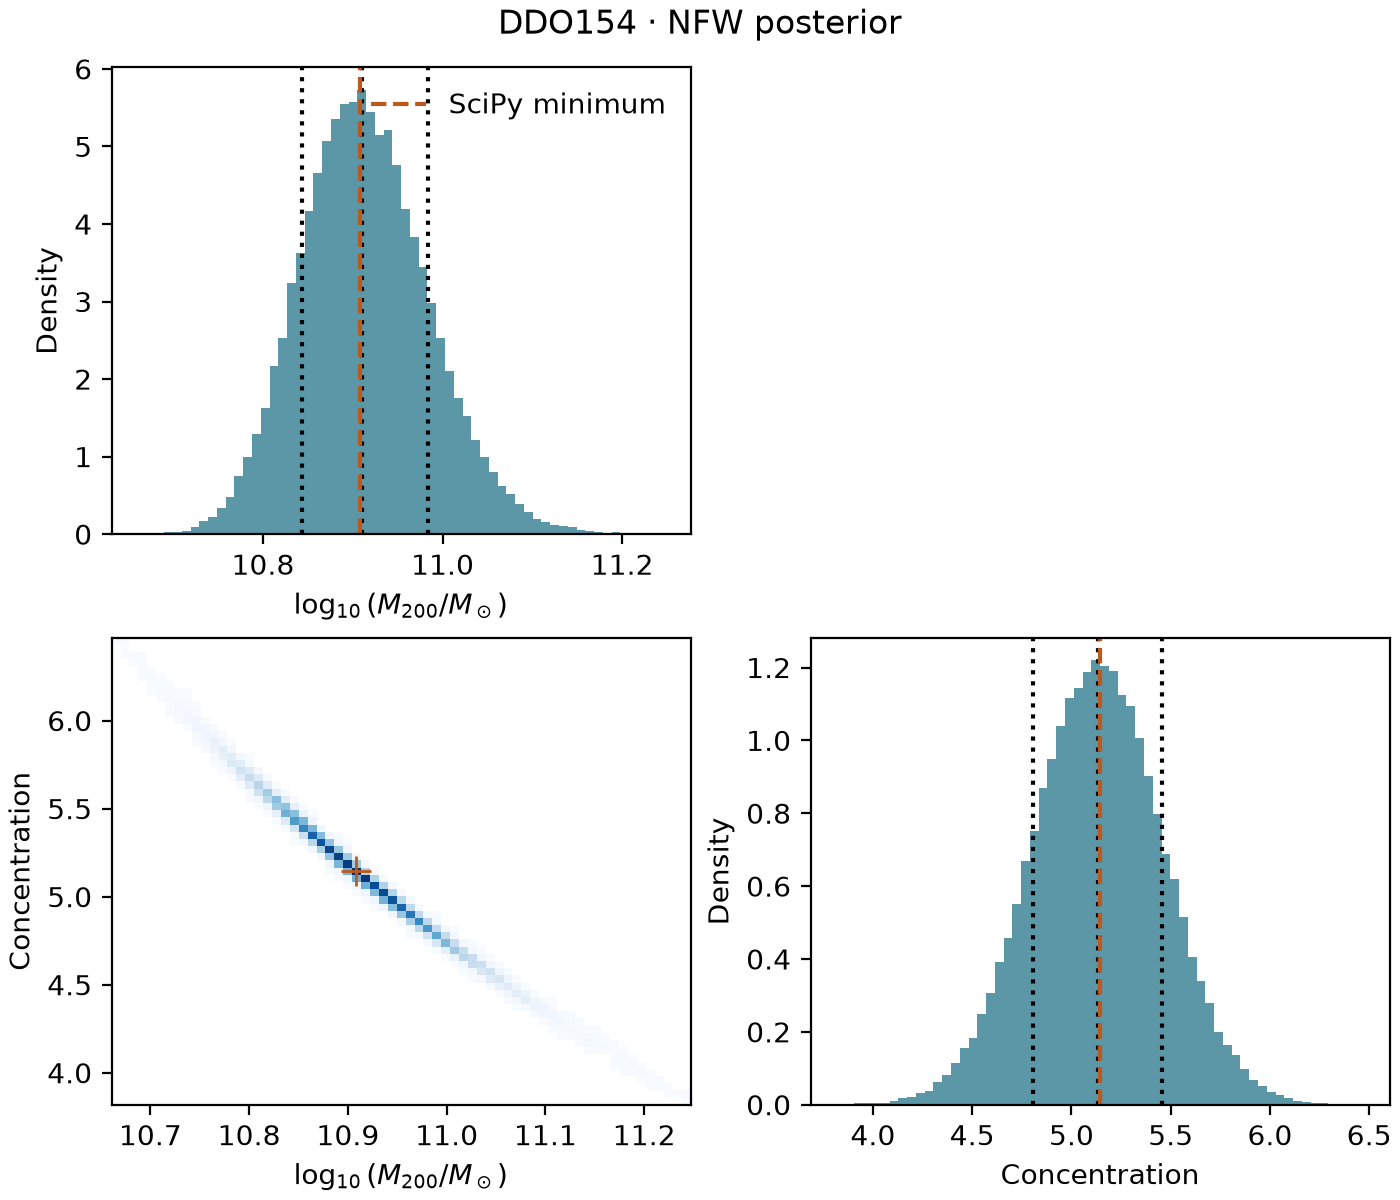

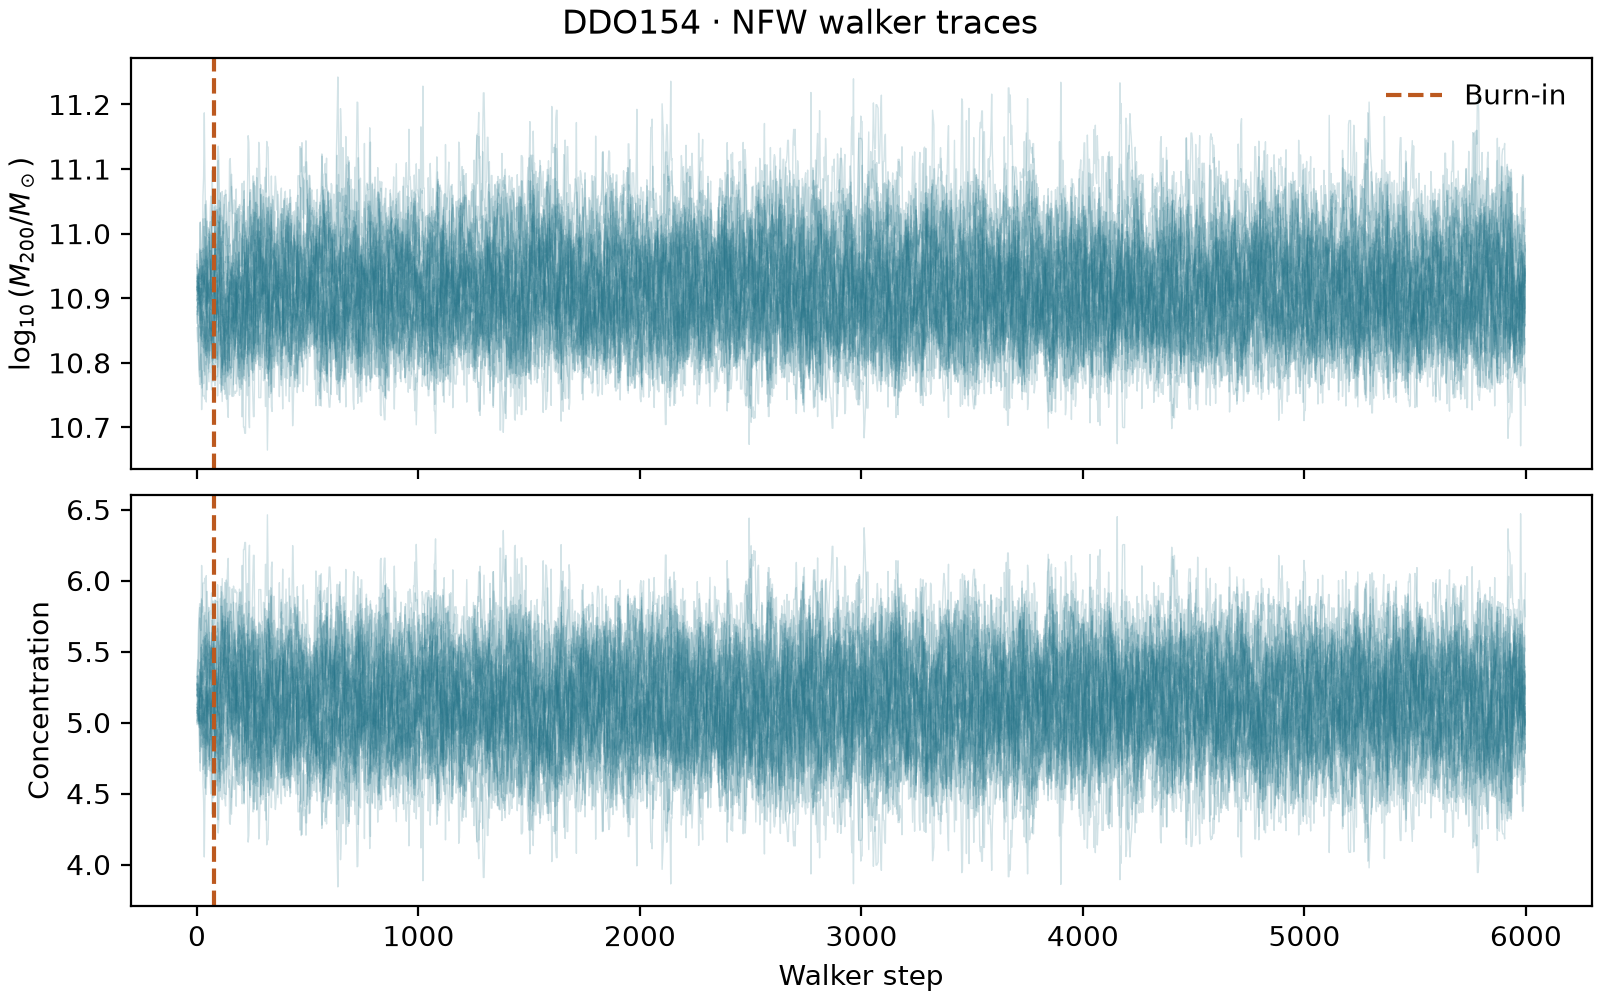

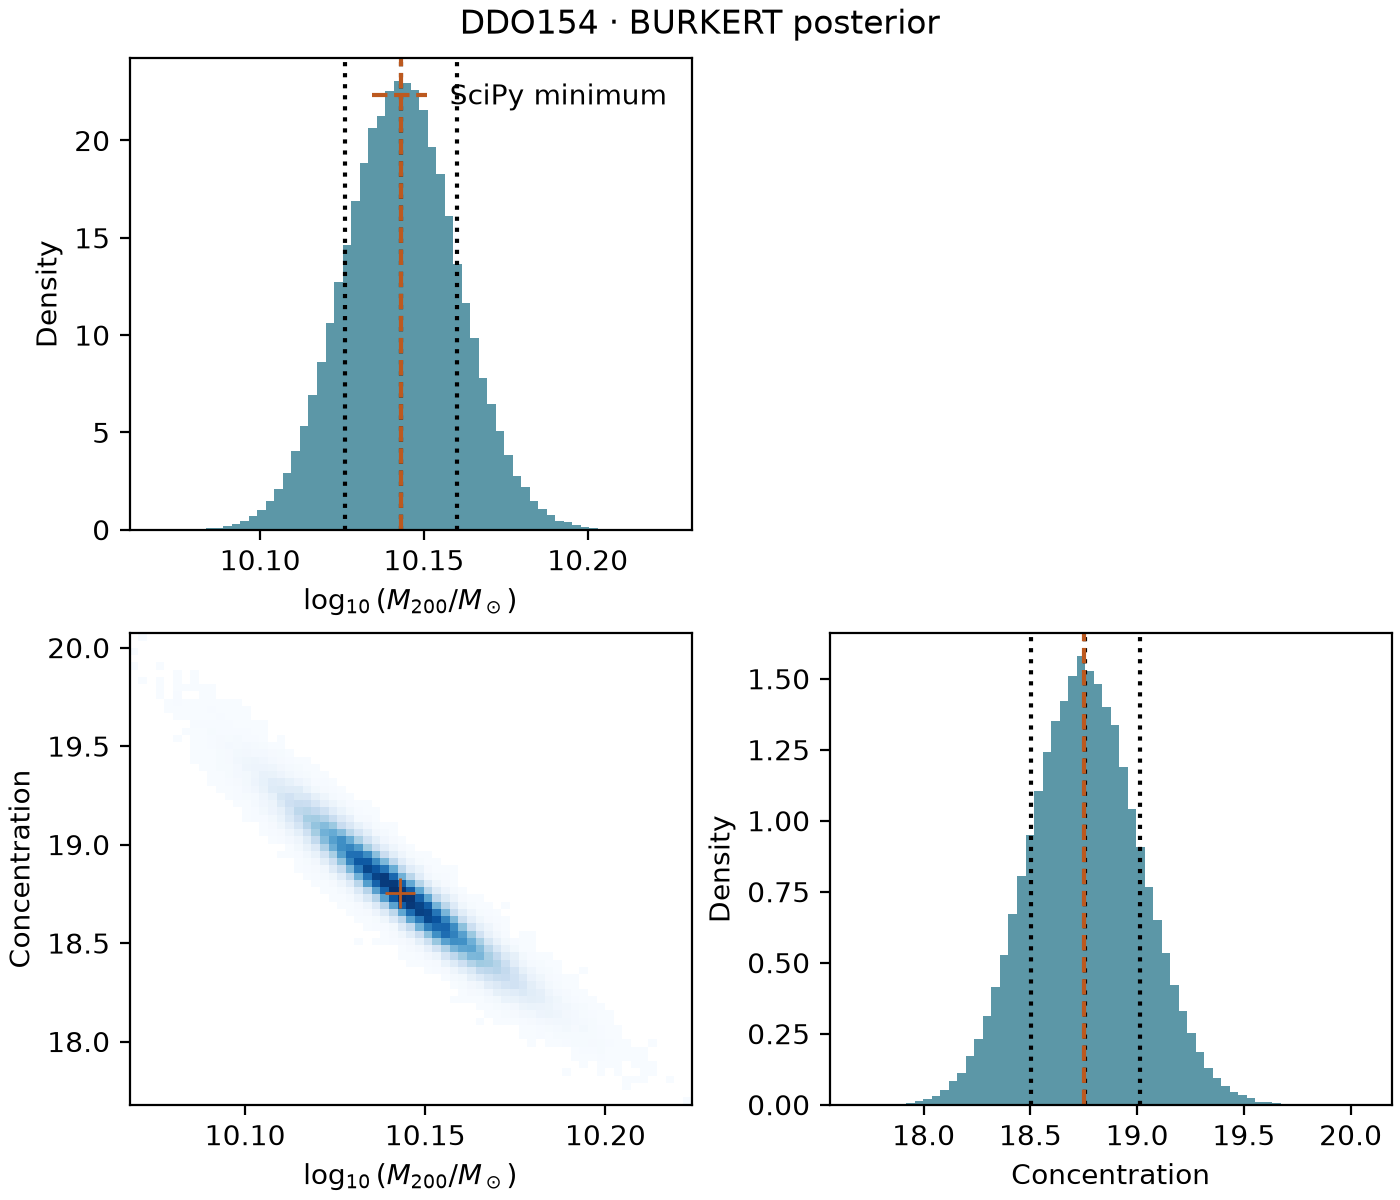

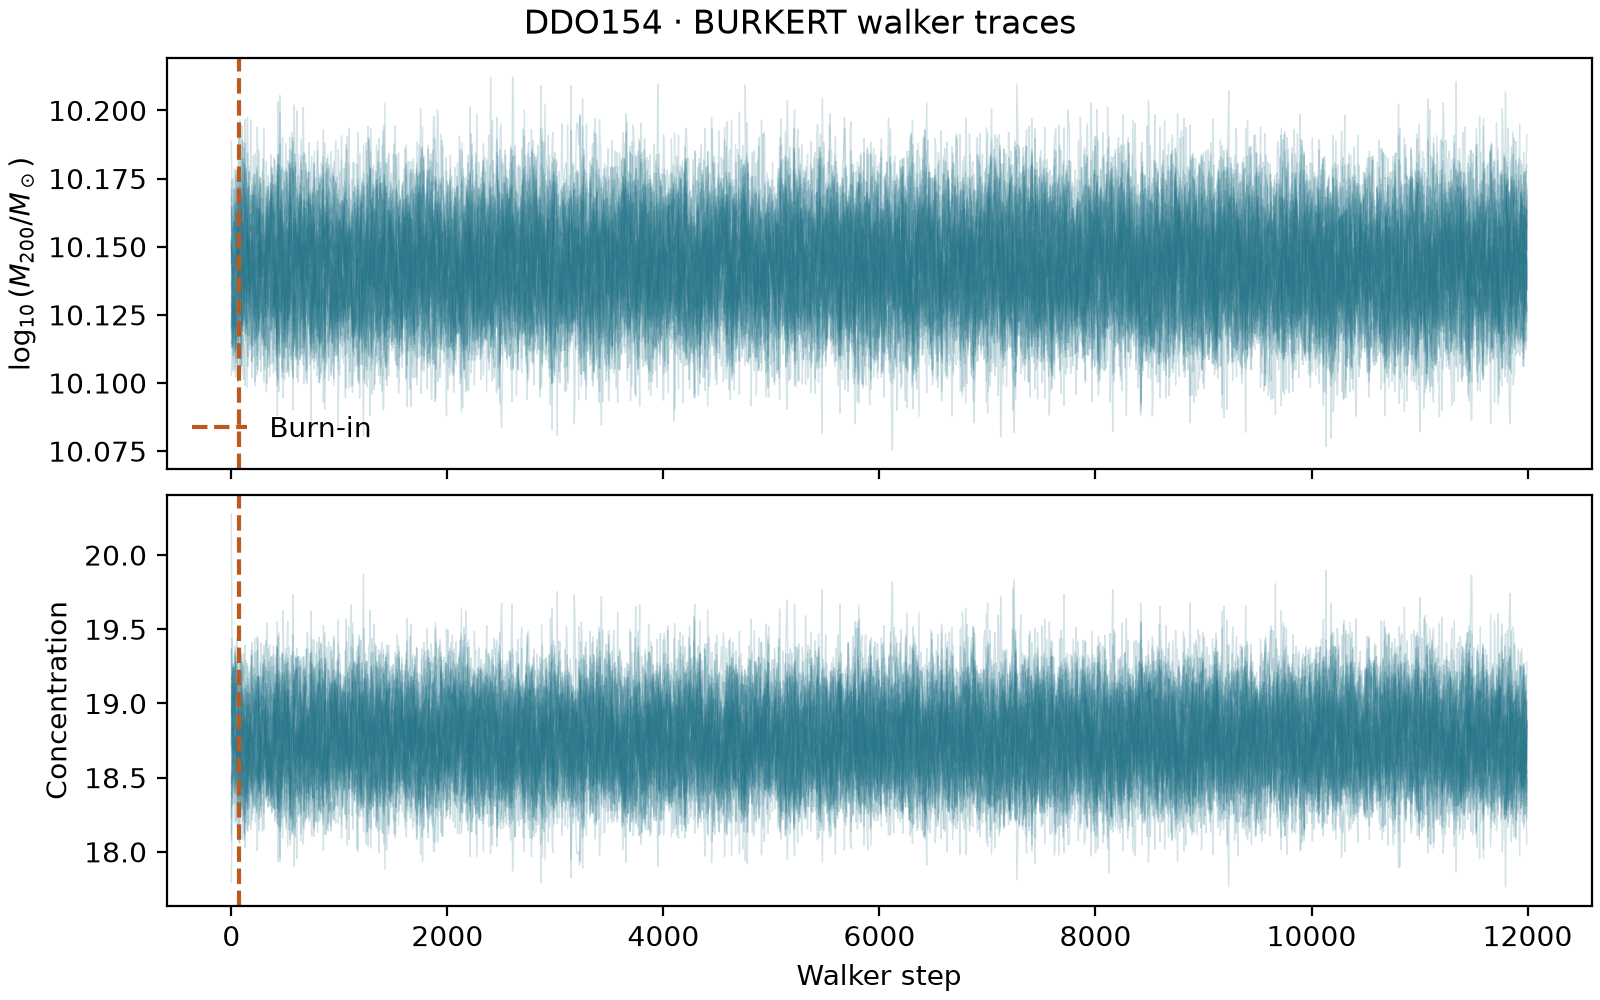

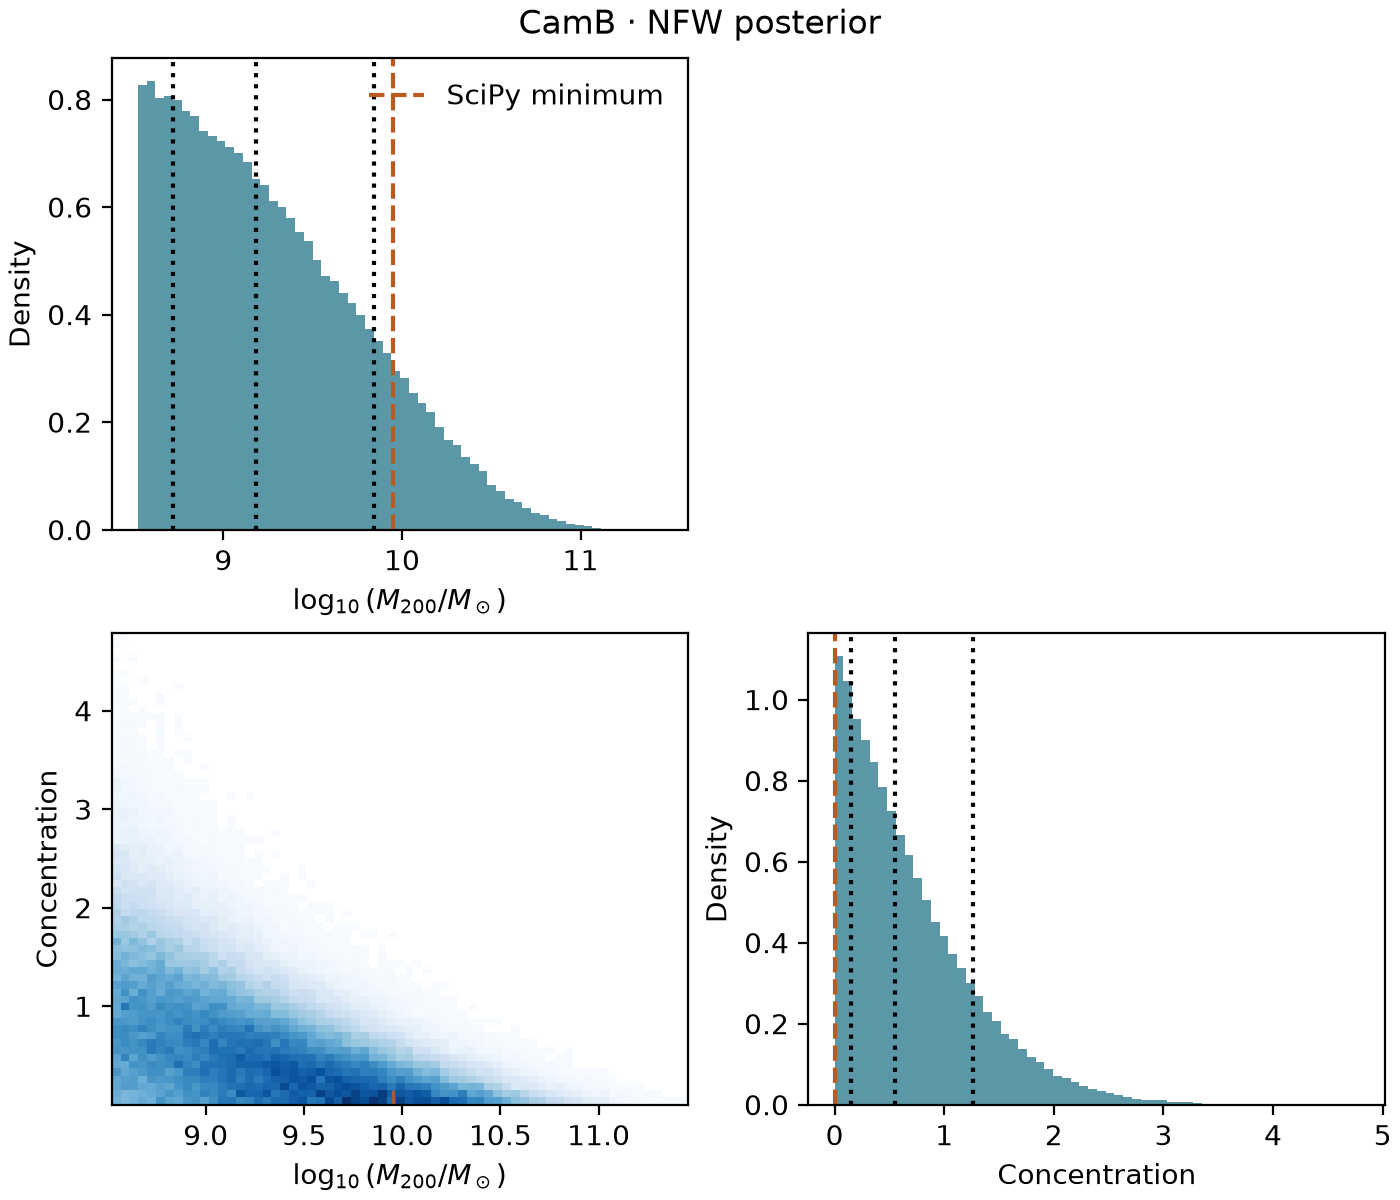

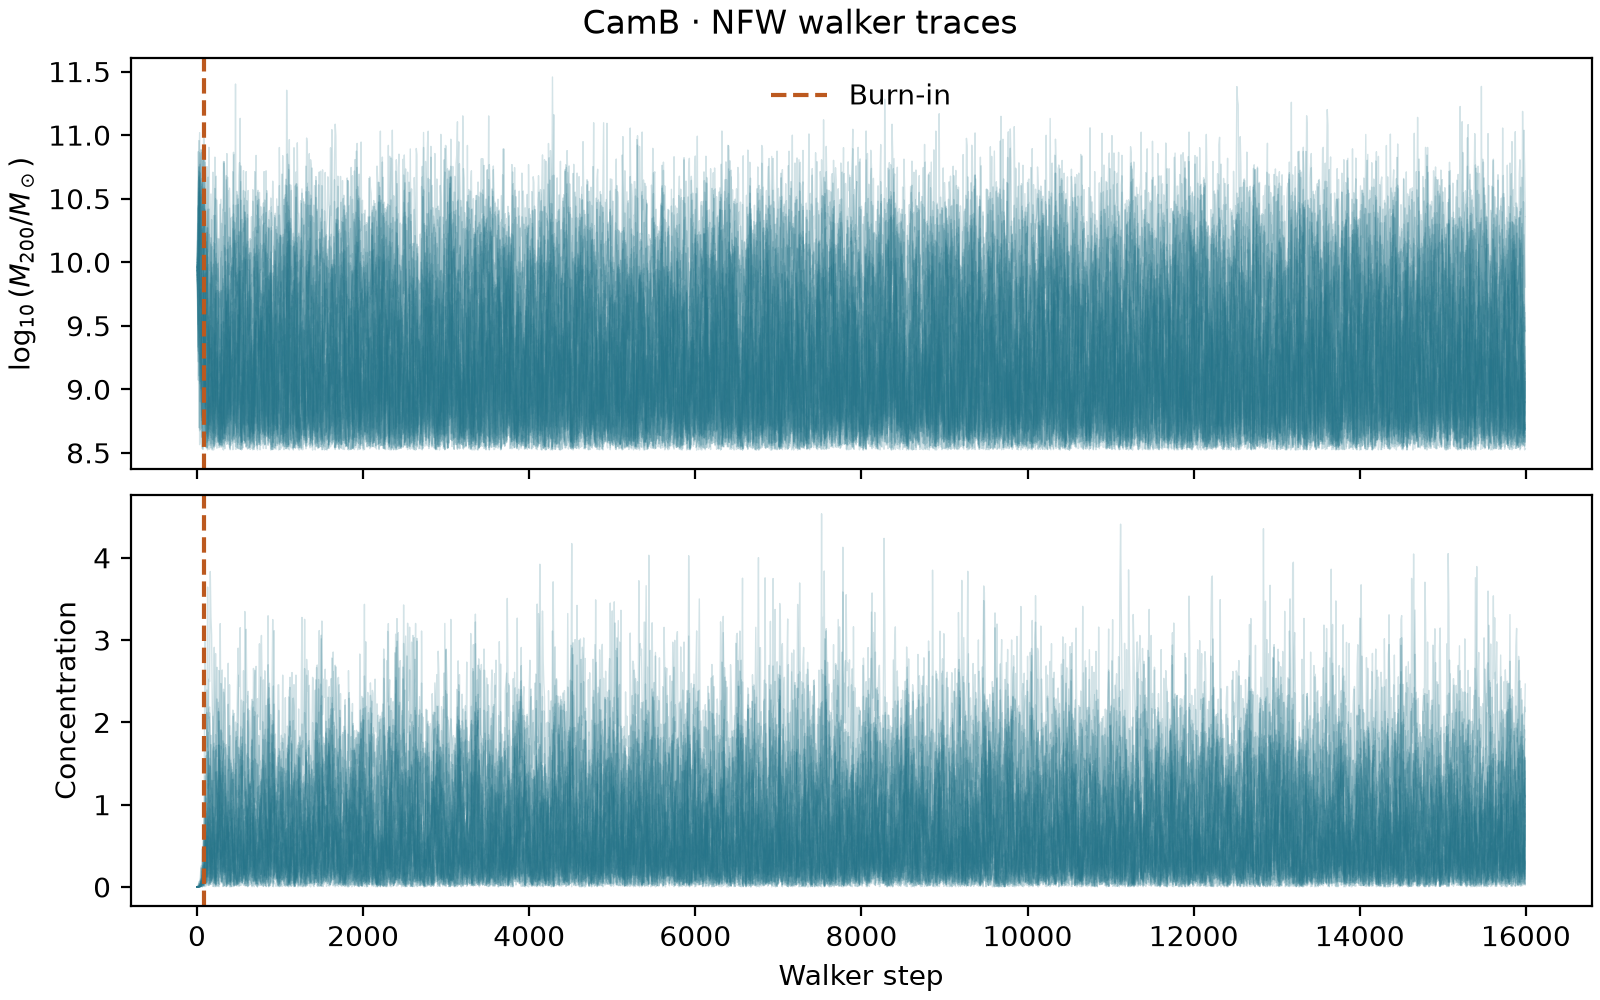

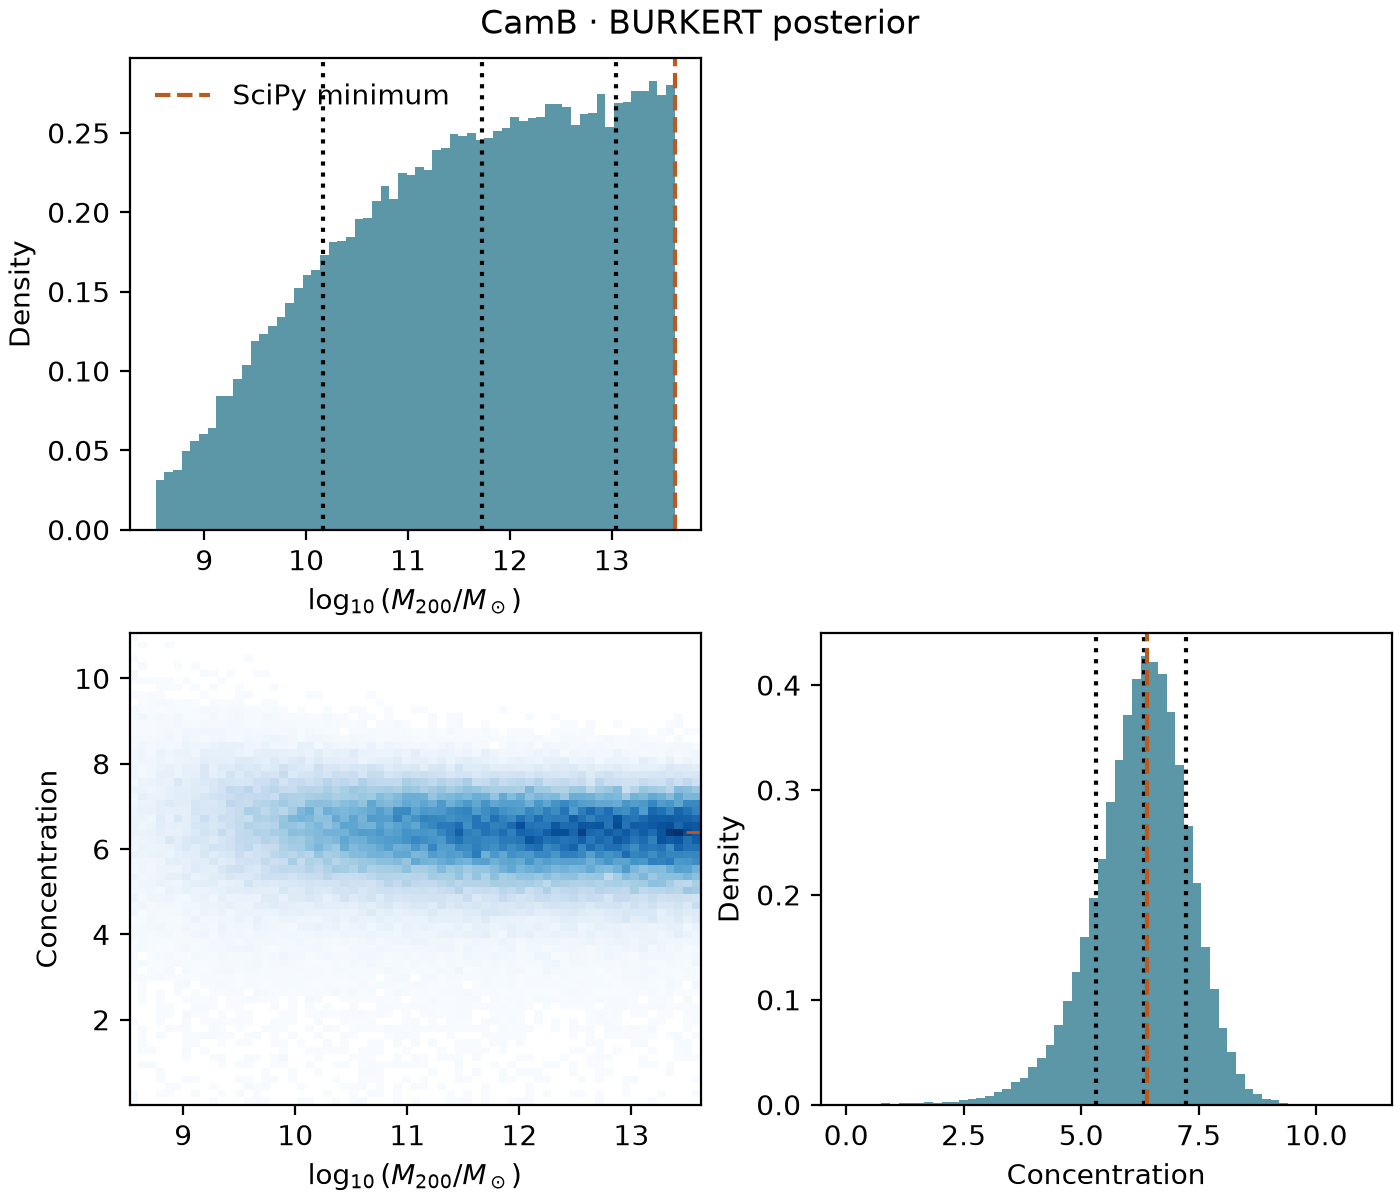

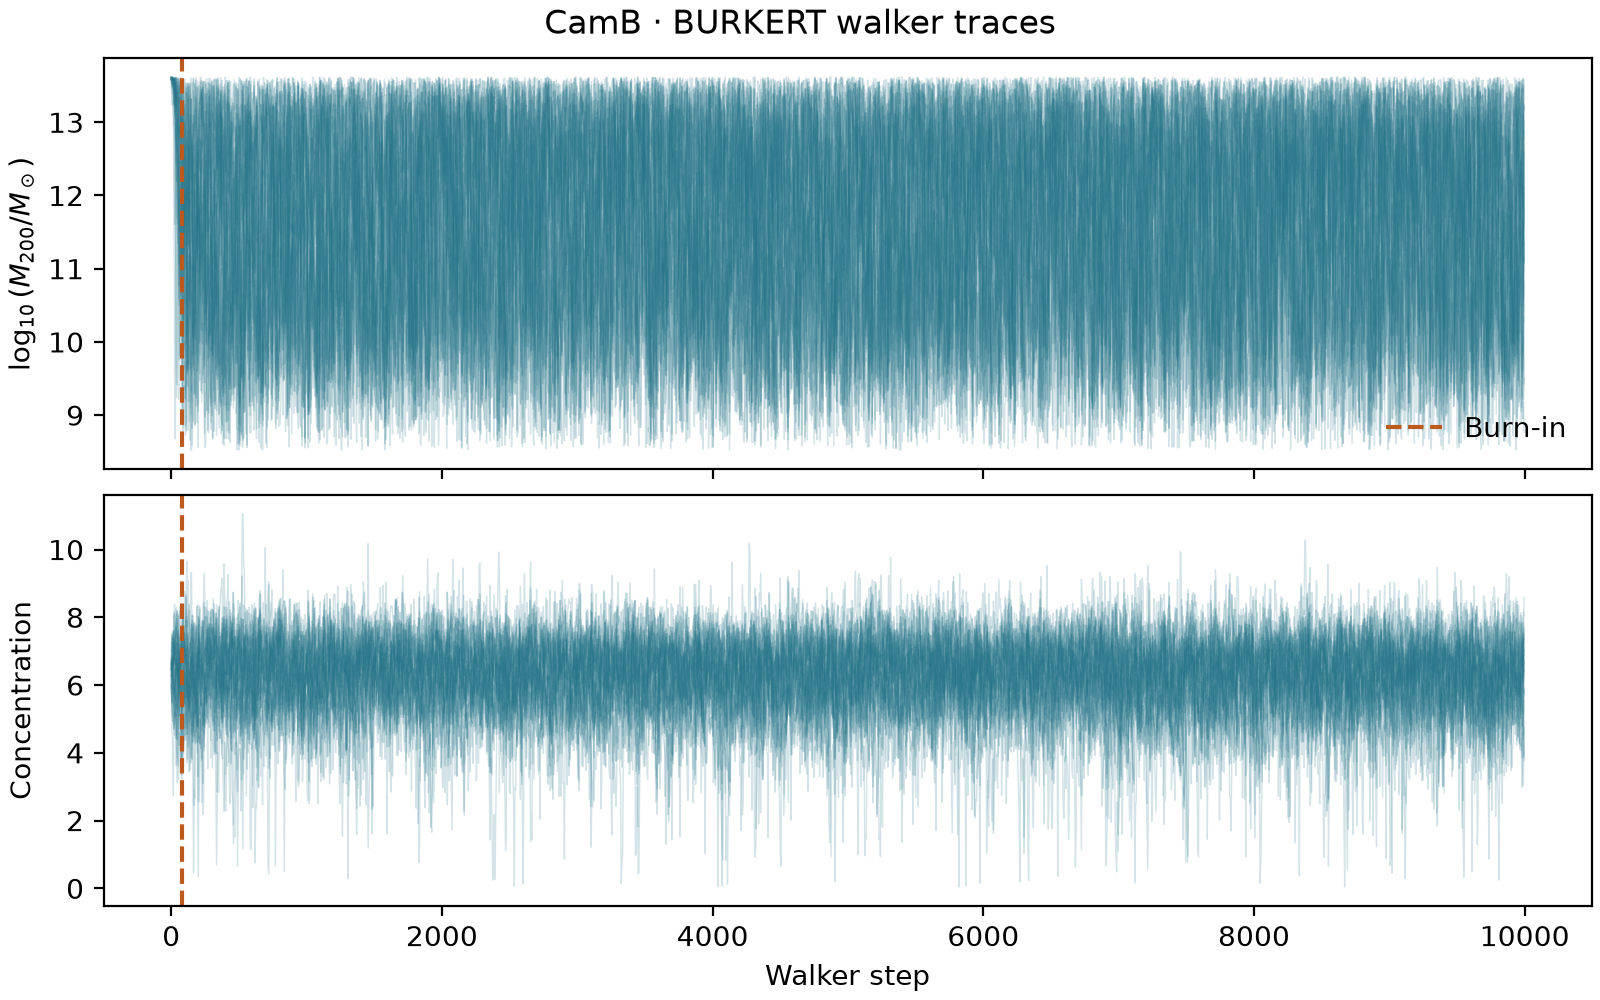

In [4]:
for galaxy in ('DDO154', 'CamB'):
    for model in ('nfw', 'burkert'):
        for kind in ('corner', 'traces'):
            plot = figures / f'{galaxy}_{model}_{kind}.png'
            if not plot.is_file():
                raise FileNotFoundError(
                    f"Missing {plot}. Set RUN_MCMC = True and rerun the notebook to generate it."
                )
            display(Image(filename=str(plot)))
